# Actividad 3.2.1 — Aprendizaje automático supervisado
**Proyecto:** Clasificación de tumores de mama (benigno / maligno) con el dataset *Breast Cancer Wisconsin (Diagnostic)* de UCI.

**Tipo de problema:** clasificación binaria · **Variable objetivo:** `diagnosis` (1 = maligno, 0 = benigno)

> Declaración de uso de IA generativa: este proyecto se elaboró con apoyo de Claude (Anthropic). El equipo revisó, ejecutó y adaptó el código.

## 1. Problema y datos

- **Problemática:** apoyar la detección temprana de tumores malignos a partir de medidas de núcleos celulares obtenidas de una biopsia por aspiración con aguja fina (FNA).
- **Fuente:** UCI Machine Learning Repository — *Breast Cancer Wisconsin (Diagnostic)*; se carga desde `sklearn.datasets` (copia incluida en el paquete).
- **Registros:** 569 · **Variables de entrada:** 30 (10 medidas × media, error estándar y valor "peor") · **Objetivo:** diagnóstico.
- **Decisión de diseño:** se usan solo las 10 variables **media** (`mean ...`). Las variables *error* y *worst* están muy correlacionadas con ellas, y así la aplicación pide solo 10 datos al usuario.
- **Métrica prioritaria:** *Recall* de la clase maligna (un falso negativo es el error más costoso), sin descuidar Precision y F1.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
for d in ("figures", "models", "data"):
    Path(d).mkdir(exist_ok=True)
sns.set_theme(style="whitegrid")

In [2]:
raw = load_breast_cancer(as_frame=True)
df = raw.frame.copy()

# En sklearn: 0 = maligno, 1 = benigno. Invertimos para que 1 = maligno (clase de interés).
df["diagnosis"] = 1 - df["target"]
df = df.drop(columns="target")
df.to_csv("data/breast_cancer_wisconsin.csv", index=False)

print("Dimensiones:", df.shape)
display(df.head())

Dimensiones: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 2. Exploración y preparación de datos

In [3]:
print("Valores faltantes totales:", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))
print("\nTipos de dato:")
print(df.dtypes.value_counts())
print("\nDistribución de la clase objetivo:")
print(df["diagnosis"].value_counts().rename({0: "Benigno", 1: "Maligno"}))
print((df["diagnosis"].value_counts(normalize=True) * 100).round(1).rename({0: "% Benigno", 1: "% Maligno"}))

Valores faltantes totales: 0
Filas duplicadas: 0

Tipos de dato:
float64    30
int64       1
Name: count, dtype: int64

Distribución de la clase objetivo:
diagnosis
Benigno    357
Maligno    212
Name: count, dtype: int64
diagnosis
% Benigno    62.7
% Maligno    37.3
Name: proportion, dtype: float64


In [4]:
features = [c for c in df.columns if c.startswith("mean ")]
display(df[features].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


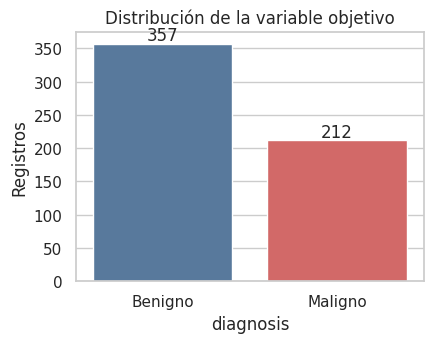

In [5]:
fig, ax = plt.subplots(figsize=(4.5, 3.6))
counts = df["diagnosis"].map({0: "Benigno", 1: "Maligno"}).value_counts()
sns.barplot(x=counts.index, y=counts.values, ax=ax, palette=["#4C78A8", "#E45756"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, str(v), ha="center")
ax.set_title("Distribución de la variable objetivo"); ax.set_ylabel("Registros")
plt.tight_layout(); plt.savefig("figures/01_distribucion_clase.png", dpi=150); plt.show()

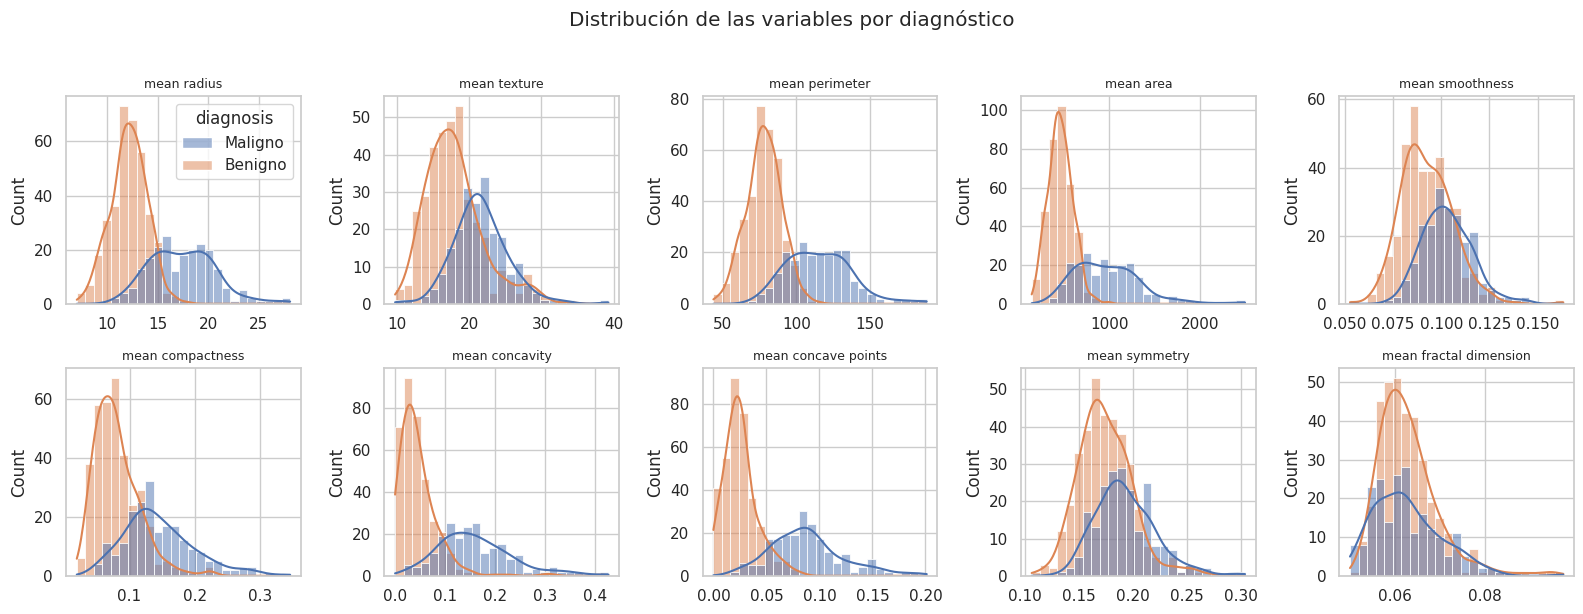

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.ravel(), features):
    sns.histplot(data=df, x=col, hue=df["diagnosis"].map({0: "Benigno", 1: "Maligno"}),
                 bins=25, kde=True, ax=ax, legend=(col == features[0]))
    ax.set_title(col, fontsize=9); ax.set_xlabel("")
plt.suptitle("Distribución de las variables por diagnóstico", y=1.02)
plt.tight_layout(); plt.savefig("figures/02_histogramas.png", dpi=130, bbox_inches="tight"); plt.show()

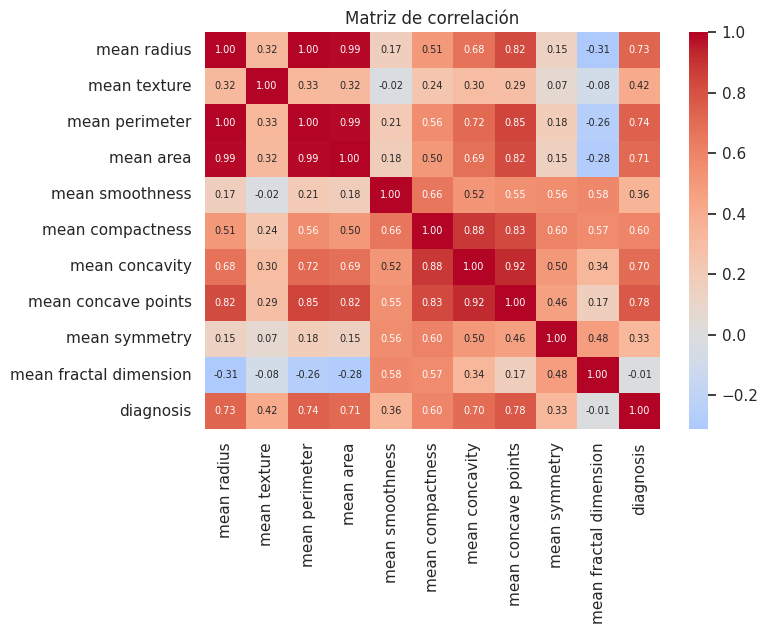

In [7]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(df[features + ["diagnosis"]].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, annot_kws={"size": 7}, ax=ax)
ax.set_title("Matriz de correlación")
plt.tight_layout(); plt.savefig("figures/03_correlacion.png", dpi=150); plt.show()

,variable,atipicos,% del total
3,mean area,25,4.4
6,mean concavity,18,3.2
5,mean compactness,16,2.8
8,mean symmetry,15,2.6
9,mean fractal dimension,15,2.6
0,mean radius,14,2.5
2,mean perimeter,13,2.3
7,mean concave points,10,1.8
1,mean texture,7,1.2
4,mean smoothness,6,1.1


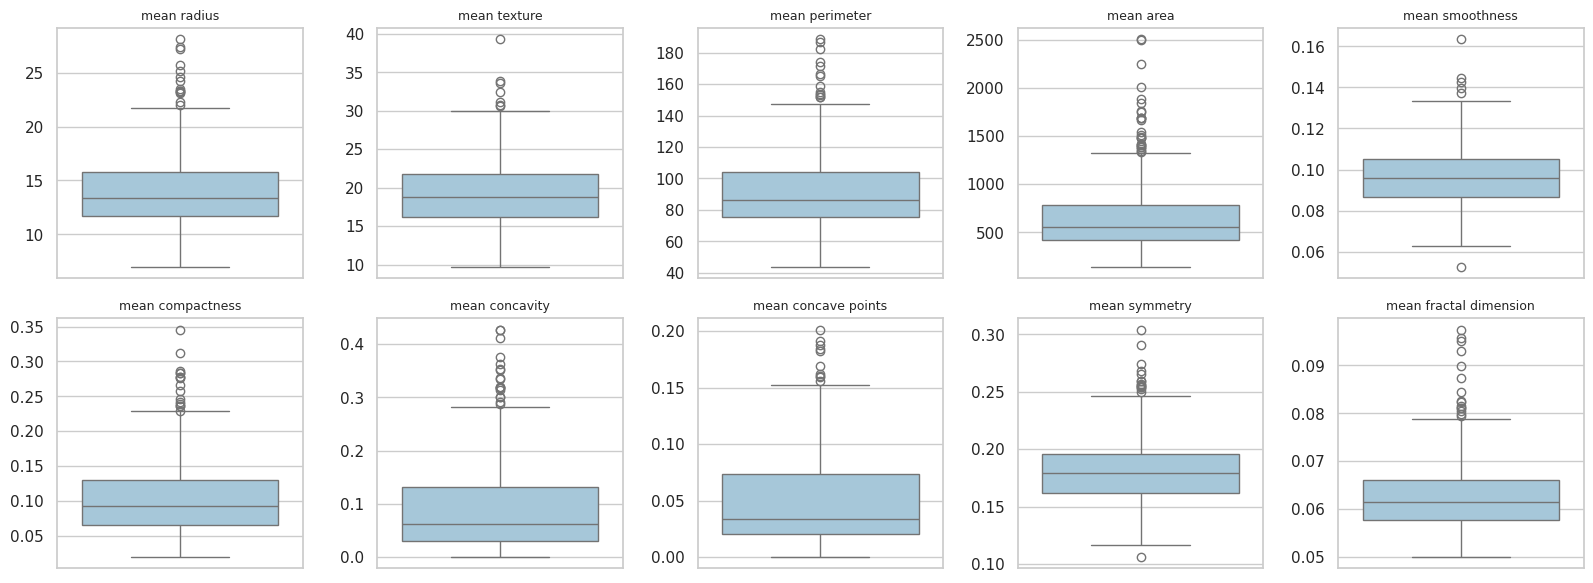

In [8]:
# Valores atípicos con la regla del rango intercuartílico (IQR)
rows = []
for col in features:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = int(((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum())
    rows.append({"variable": col, "atipicos": n_out, "% del total": round(100 * n_out / len(df), 1)})
outliers = pd.DataFrame(rows).sort_values("atipicos", ascending=False)
display(outliers)

fig, axes = plt.subplots(2, 5, figsize=(16, 6))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(y=df[col], ax=ax, color="#9ecae1"); ax.set_title(col, fontsize=9); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("figures/04_boxplots.png", dpi=130); plt.show()

**Hallazgos de la exploración**
- No hay valores faltantes ni duplicados, y todas las variables ya son numéricas (no se requiere codificación).
- Las clases están moderadamente desbalanceadas (~63 % benigno / ~37 % maligno) → se usa **partición estratificada** y se reporta Recall/F1 además de Accuracy.
- Existen valores atípicos (sobre todo en área y concavidad), pero son **mediciones clínicamente plausibles** (tumores grandes), por lo que **no se eliminan**; se usa `StandardScaler` y modelos poco sensibles a ellos.
- Las variables de tamaño (radio, perímetro, área) están fuertemente correlacionadas entre sí.

In [9]:
X = df[features]
y = df["diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print("% maligno en train:", round(y_train.mean() * 100, 1), "| en test:", round(y_test.mean() * 100, 1))

Entrenamiento: (455, 10) | Prueba: (114, 10)
% maligno en train: 37.4 | en test: 36.8


## 3. Entrenamiento y comparación de modelos
Se comparan **KNN, SVM, Árbol de Decisión y Random Forest**. Cada modelo va dentro de un `Pipeline` con `StandardScaler` (el escalado se ajusta solo con datos de entrenamiento, evitando fuga de información) y sus hiperparámetros se optimizan con `GridSearchCV` (validación cruzada estratificada de 5 pliegues, métrica F1). El **modelo ganador se elige con validación cruzada repetida** sobre el conjunto de entrenamiento y no con el conjunto de prueba (que se reserva para la evaluación final).

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

candidates = {
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [3, 5, 7, 9, 11], "clf__weights": ["uniform", "distance"]}),
    "SVM": (SVC(probability=True, random_state=RANDOM_STATE),
            {"clf__C": [0.1, 1, 10, 100], "clf__gamma": ["scale", 0.01, 0.1], "clf__kernel": ["rbf", "linear"]}),
    "Árbol de Decisión": (DecisionTreeClassifier(random_state=RANDOM_STATE),
            {"clf__max_depth": [3, 4, 5, 7, None], "clf__min_samples_leaf": [1, 3, 5]}),
    "Random Forest": (RandomForestClassifier(random_state=RANDOM_STATE),
            {"clf__n_estimators": [100, 300], "clf__max_depth": [None, 5, 10], "clf__min_samples_leaf": [1, 2]}),
}

fitted, rows = {}, []
for name, (estimator, grid) in candidates.items():
    pipe = Pipeline([("scaler", StandardScaler()), ("clf", estimator)])
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1).fit(X_train, y_train)
    best = gs.best_estimator_
    fitted[name] = best
    pred = best.predict(X_test)
    proba = best.predict_proba(X_test)[:, 1]
    rows.append({
        "Modelo": name,
        "F1 (CV)": gs.best_score_,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC AUC": roc_auc_score(y_test, proba),
        "Mejores hiperparámetros": {k.replace("clf__", ""): v for k, v in gs.best_params_.items()},
    })

results = pd.DataFrame(rows).sort_values("F1 (CV)", ascending=False).reset_index(drop=True)
results.to_csv("data/tabla_comparativa.csv", index=False)
display(results.round(4))

,Modelo,F1 (CV),Accuracy,Precision,Recall,F1,ROC AUC,Mejores hiperparámetros
0,Random Forest,0.9281,0.9386,0.9268,0.9048,0.9157,0.9845,"{'max_depth': 5, 'min_samples_leaf': 2, 'n_est..."
1,SVM,0.9249,0.9737,0.9756,0.9524,0.9639,0.9891,"{'C': 100, 'gamma': 0.01, 'kernel': 'rbf'}"
2,Árbol de Decisión,0.9243,0.9211,0.9231,0.8571,0.8889,0.9277,"{'max_depth': 3, 'min_samples_leaf': 3}"
3,KNN,0.9217,0.9474,0.9091,0.9524,0.9302,0.9747,"{'n_neighbors': 7, 'weights': 'uniform'}"


In [11]:
# Las diferencias de F1 (CV) entre modelos son muy pequeñas. Para decidir con más rigor se repite la
# validación cruzada (5 pliegues x 3 repeticiones) sobre los datos de ENTRENAMIENTO con los
# hiperparámetros ya optimizados. Criterio de selección: mayor F1 medio; desempate por Recall.
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)
rows = []
for name, model in fitted.items():
    sc = cross_validate(model, X_train, y_train, cv=rcv, scoring=["f1", "recall", "precision"], n_jobs=-1)
    rows.append({"Modelo": name,
                 "F1 CV-rep (media)": sc["test_f1"].mean(), "F1 CV-rep (desv.)": sc["test_f1"].std(),
                 "Recall CV-rep": sc["test_recall"].mean(), "Precision CV-rep": sc["test_precision"].mean()})
cv_rep = pd.DataFrame(rows).sort_values(["F1 CV-rep (media)", "Recall CV-rep"], ascending=False).reset_index(drop=True)
cv_rep.to_csv("data/tabla_cv_repetida.csv", index=False)
display(cv_rep.round(4))

,Modelo,F1 CV-rep (media),F1 CV-rep (desv.),Recall CV-rep,Precision CV-rep
0,SVM,0.9198,0.0302,0.9039,0.9378
1,Random Forest,0.9196,0.0369,0.9098,0.9310
2,KNN,0.9135,0.0359,0.8961,0.9335
3,Árbol de Decisión,0.9096,0.0442,0.9078,0.9143


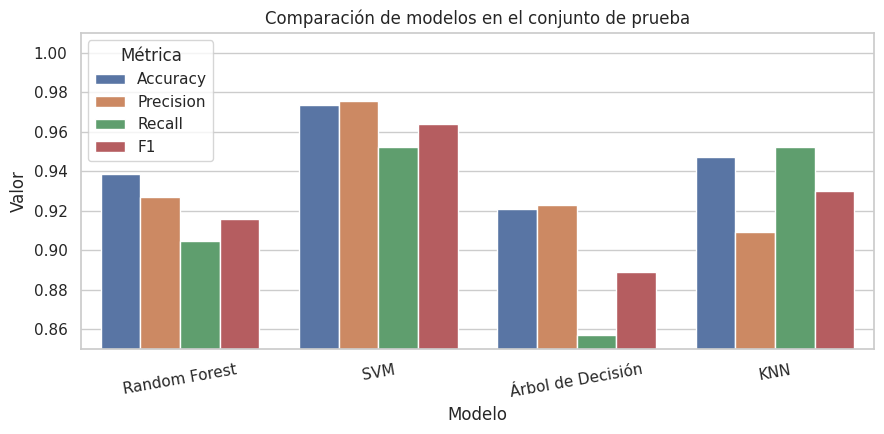

In [12]:
metric_cols = ["Accuracy", "Precision", "Recall", "F1"]
plot_df = results.melt(id_vars="Modelo", value_vars=metric_cols, var_name="Métrica", value_name="Valor")
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=plot_df, x="Modelo", y="Valor", hue="Métrica", ax=ax)
ax.set_ylim(0.85, 1.01); ax.set_title("Comparación de modelos en el conjunto de prueba")
plt.xticks(rotation=10); plt.tight_layout()
plt.savefig("figures/05_comparacion_modelos.png", dpi=150); plt.show()

## 4. Evaluación del modelo ganador

Modelo ganador (mejor F1 en validación cruzada repetida): SVM
              precision    recall  f1-score   support

     Benigno      0.973     0.986     0.979        72
     Maligno      0.976     0.952     0.964        42

    accuracy                          0.974       114
   macro avg      0.974     0.969     0.972       114
weighted avg      0.974     0.974     0.974       114



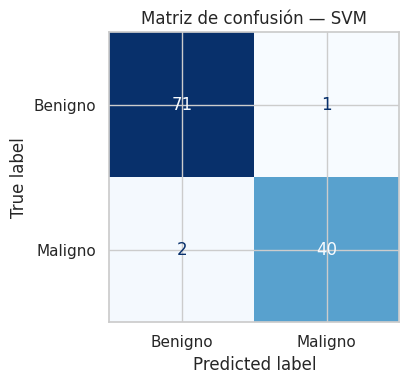

In [13]:
winner_name = cv_rep.loc[0, "Modelo"]
winner = fitted[winner_name]
print("Modelo ganador (mejor F1 en validación cruzada repetida):", winner_name)

y_pred = winner.predict(X_test)
print(classification_report(y_test, y_pred, target_names=["Benigno", "Maligno"], digits=3))

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred), display_labels=["Benigno", "Maligno"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Matriz de confusión — {winner_name}")
plt.tight_layout(); plt.savefig("figures/06_matriz_confusion.png", dpi=150); plt.show()

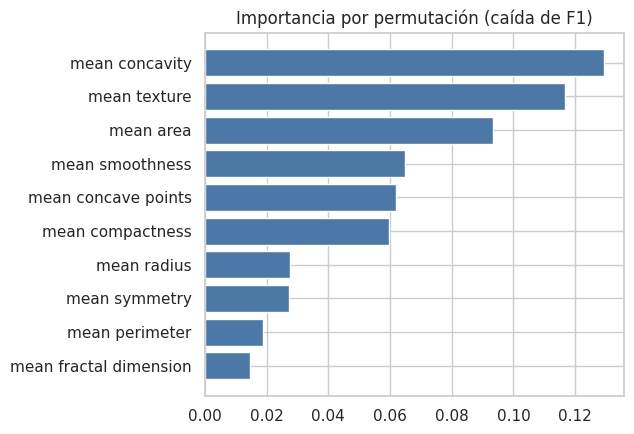

,variable,importancia
6,mean concavity,0.1294
1,mean texture,0.1167
3,mean area,0.0935
4,mean smoothness,0.0650
7,mean concave points,0.0620
5,mean compactness,0.0598
0,mean radius,0.0275
8,mean symmetry,0.0273
2,mean perimeter,0.0188
9,mean fractal dimension,0.0145


In [14]:
imp = permutation_importance(winner, X_test, y_test, scoring="f1", n_repeats=30, random_state=RANDOM_STATE)
imp_df = (pd.DataFrame({"variable": features, "importancia": imp.importances_mean})
          .sort_values("importancia", ascending=True))
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.barh(imp_df["variable"], imp_df["importancia"], color="#4C78A8")
ax.set_title("Importancia por permutación (caída de F1)")
plt.tight_layout(); plt.savefig("figures/07_importancia_variables.png", dpi=150); plt.show()
display(imp_df.sort_values("importancia", ascending=False).round(4))

## 5. Guardado del modelo para la aplicación

In [15]:
metadata = {
    "modelo": winner_name,
    "features": features,
    "rangos": {c: {"min": float(df[c].min()), "max": float(df[c].max()),
                   "mediana": float(df[c].median())} for c in features},
    "clases": {"0": "Benigno", "1": "Maligno"},
    "metricas_prueba": {m: float(results.loc[results["Modelo"] == winner_name, m].iloc[0]) for m in metric_cols + ["ROC AUC"]},
}
joblib.dump(winner, "models/modelo.joblib")
Path("models/metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

# Prueba rápida de carga y predicción
loaded = joblib.load("models/modelo.joblib")
ejemplo = X_test.iloc[[0]]
print("Caso de prueba — real:", int(y_test.iloc[0]), "| predicción:", int(loaded.predict(ejemplo)[0]),
      "| prob. maligno:", round(float(loaded.predict_proba(ejemplo)[0, 1]), 3))

Caso de prueba — real: 0 | predicción: 0 | prob. maligno: 0.0


## 6. Conclusiones y limitaciones
- Se compararon cuatro algoritmos con las mismas particiones y validación cruzada; el ganador se elige con validación cruzada repetida (F1, desempate por Recall) y se confirma en el conjunto de prueba.
- **Limitaciones:** dataset pequeño (569 casos) y de una sola fuente; la partición de prueba tiene pocos casos, por lo que las métricas tienen incertidumbre; el modelo no se validó clínicamente.
- **Uso responsable:** esta herramienta es **educativa** y no sustituye un diagnóstico médico.